# NIST TN 1822 — Verif.2.2: Speed on stairs - downward

Single agent traverses 100 m of stair downward at 1.0 m/s. Stair extended to 120 m with 10 m + 10 m buffers; see MODIFICATIONS.md.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 11:40 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles

## Load and run the scenario

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Nist-2-2-stairs-down.zip"
scenario = load_scenario(str(SCENARIO_ZIP))
print(scenario.summary())
result = run_scenario(scenario, seed=42)

Scenario: scenario_files/Nist-2-2-stairs-down.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      160s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      1
  Agents:        ~1
  Journey elems: 2
  Route:         1 distribution, 0 checkpoint, 1 exit
  Sequence:      jps-distributions_0 -> jps-exits_0
    jps-distributions_0: 1 agents


## Measure walking speed across the 100 m segment

In [6]:
df = result.trajectory_dataframe().sort_values(['id', 'frame'])
MEAS_START_X = 110.0
MEAS_END_X = 10.0
DIRECTION = 'left'
rows = []
for agent_id, sub in df.groupby('id'):
    sub = sub.reset_index(drop=True)
    if DIRECTION == 'right':
        t_in_idx = sub[sub.x >= MEAS_START_X].index.min()
        t_out_idx = sub[sub.x >= MEAS_END_X].index.min()
    else:
        t_in_idx = sub[sub.x <= MEAS_START_X].index.min()
        t_out_idx = sub[sub.x <= MEAS_END_X].index.min()
    if pd.isna(t_in_idx) or pd.isna(t_out_idx):
        continue
    t_in = sub.loc[t_in_idx, 'frame'] / result.frame_rate
    t_out = sub.loc[t_out_idx, 'frame'] / result.frame_rate
    rows.append({'id': int(agent_id), 't_in_s': t_in, 't_out_s': t_out, 'transit_s': t_out - t_in})
transit = pd.DataFrame(rows)
transit['speed_m_s'] = abs(MEAS_END_X - MEAS_START_X) / transit['transit_s']
transit

,id,t_in_s,t_out_s,transit_s,speed_m_s
0,1,9.3,109.3,100.0,1.0


## Scenario figure

The ZIP defines no zones: the stair is a straight corridor walked at v0 = 1.0 m/s, so the test checks the speed the model delivers over the 100 m segment. The agent walks from right to left.

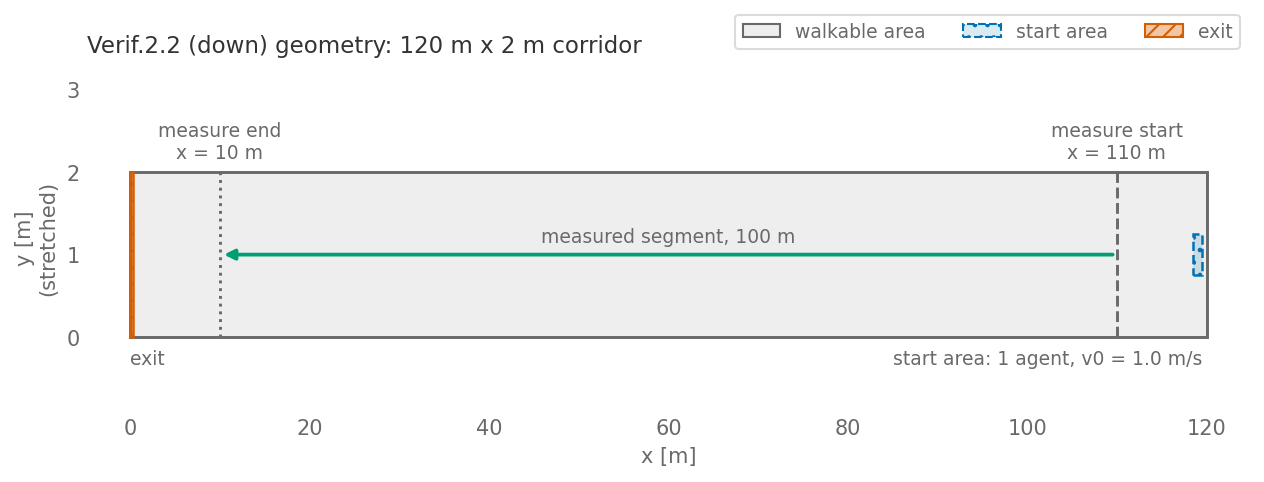

In [7]:
# Scenario geometry from the loaded ZIP; measuring segment from the measure cell.
minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(10, 3.0))
    handles = vv_draw_scenario(ax, scenario)
    ax.set_aspect("auto")
    ax.set_ylim(miny - 0.9, maxy + 1.3)
    ax.set_ylabel("y [m]\n(stretched)")
    for x, ls, name in ((MEAS_START_X, "--", "measure start"), (MEAS_END_X, ":", "measure end")):
        ax.plot([x, x], [miny, maxy], color="dimgrey", ls=ls, lw=1.4, zorder=4)
        ax.text(x, maxy + 0.12, f"{name}\nx = {x:g} m", ha="center", va="bottom",
                color="dimgrey", fontsize=9)
    ymid = 0.5 * (miny + maxy)
    ax.annotate("", xy=(MEAS_END_X, ymid), xytext=(MEAS_START_X, ymid), zorder=5,
                arrowprops={"arrowstyle": "-|>", "color": VV_GREEN, "lw": 1.8})
    ax.text(0.5 * (MEAS_START_X + MEAS_END_X), ymid + 0.1,
            f"measured segment, {abs(MEAS_END_X - MEAS_START_X):g} m", ha="center", va="bottom",
            color="dimgrey", fontsize=9, zorder=5)
    for dist in scenario.distributions.values():
        bx0, _, bx1, _ = Polygon(dist["coordinates"]).bounds
        p = dist["parameters"]
        left = 0.5 * (bx0 + bx1) < 0.5 * (minx + maxx)
        ax.text(bx0 if left else bx1, miny - 0.15,
                f"start area: {p['number']} agent, v0 = {p['v0']} m/s",
                ha="left" if left else "right", va="top", color="dimgrey", fontsize=9)
    for ex in scenario.exits.values():
        ex_minx, _, ex_maxx, _ = Polygon(ex["coordinates"]).bounds
        left = 0.5 * (ex_minx + ex_maxx) < 0.5 * (minx + maxx)
        ax.text(ex_minx if left else ex_maxx, miny - 0.15, "exit",
                ha="left" if left else "right", va="top", color="dimgrey", fontsize=9)
    ax.set_title("Verif.2.2 (down) geometry: " f"{maxx - minx:g} m x {maxy - miny:g} m corridor", loc="left")
    ax.legend(handles=handles, loc="lower right", bbox_to_anchor=(1.0, 1.02), ncol=3)
    plt.show()

## Plot trajectory x vs t

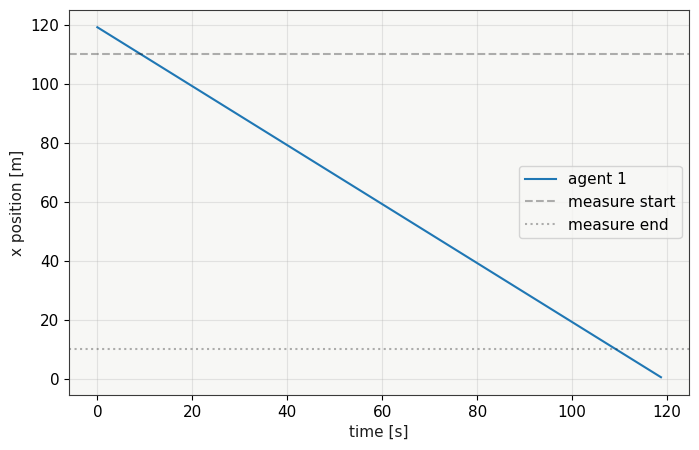

In [8]:
fig, ax = plt.subplots()
for agent_id, sub in df.groupby('id'):
    ax.plot(sub.frame / result.frame_rate, sub.x, label=f'agent {agent_id}')
ax.axhline(MEAS_START_X, color='k', ls='--', alpha=0.3, label='measure start')
ax.axhline(MEAS_END_X, color='k', ls=':', alpha=0.3, label='measure end')
ax.set_xlabel('time [s]')
ax.set_ylabel('x position [m]')
ax.legend()
plt.show()

## Acceptance

In [9]:
TARGET = 1.0
TOL = 0.05
observed = transit['speed_m_s'].mean()
print(f'observed mean speed = {observed:.3f} m/s; target = {TARGET} m/s')
assert abs(observed - TARGET) <= TOL, (observed, TARGET)

observed mean speed = 1.000 m/s; target = 1.0 m/s


## Result figure

Speed over the measured 100 m segment against the accepted band 1.0 ± 0.05 m/s.

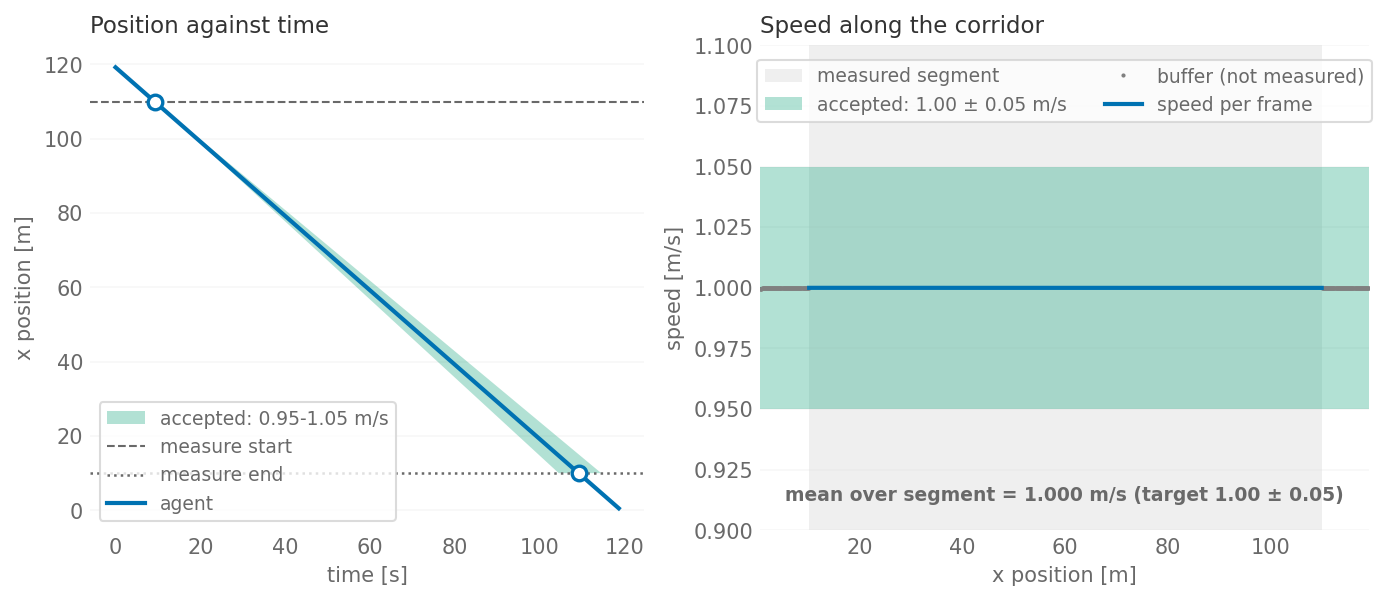

In [10]:
# Position-time curve and speed along the corridor against the acceptance band.
row = transit.iloc[0]
agent = df[df["id"] == row["id"]].sort_values("frame")
t = agent["frame"].to_numpy() / result.frame_rate
x = agent["x"].to_numpy()
seg_len = abs(MEAS_END_X - MEAS_START_X)
t_in, t_out = row["t_in_s"], row["t_out_s"]
v_lo, v_hi = TARGET - TOL, TARGET + TOL
with plt.rc_context(VV_RC):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
    # (a) x(t): the accepted arrival window at the segment end is the cone for 0.95-1.05 m/s.
    ax1.fill([t_in, t_in + seg_len / v_hi, t_in + seg_len / v_lo],
             [MEAS_START_X, MEAS_END_X, MEAS_END_X], color=VV_GREEN, alpha=0.3, lw=0,
             label=f"accepted: {v_lo:.2f}-{v_hi:.2f} m/s")
    ax1.axhline(MEAS_START_X, color="dimgrey", ls="--", lw=1.0, label="measure start")
    ax1.axhline(MEAS_END_X, color="dimgrey", ls=":", lw=1.2, label="measure end")
    ax1.plot(t, x, color=VV_BLUE, lw=2.0, label="agent")
    ax1.plot([t_in, t_out], [MEAS_START_X, MEAS_END_X], "o", color=VV_BLUE, mfc="white", ms=7, mew=1.6)
    ax1.set_xlabel("time [s]")
    ax1.set_ylabel("x position [m]")
    ax1.set_title("Position against time", loc="left")
    ax1.legend(loc="lower right" if DIRECTION == "right" else "lower left")
    ax1.grid(axis="x", visible=False)
    # (b) speed per frame against x; the criterion applies to the mean over the shaded segment.
    xm = 0.5 * (x[1:] + x[:-1])
    v = np.abs(np.diff(x)) * result.frame_rate
    seg_lo, seg_hi = sorted((MEAS_START_X, MEAS_END_X))
    in_seg = (xm >= seg_lo) & (xm <= seg_hi)
    ax2.axvspan(seg_lo, seg_hi, color="lightgrey", alpha=0.35, lw=0, label="measured segment")
    ax2.axhspan(v_lo, v_hi, color=VV_GREEN, alpha=0.3, lw=0, label=f"accepted: {TARGET:.2f} ± {TOL:.2f} m/s")
    ax2.axhline(TARGET, color=VV_GREEN, lw=1.0)
    ax2.plot(xm[~in_seg], v[~in_seg], ".", color="grey", ms=2, label="buffer (not measured)")
    ax2.plot(xm[in_seg], v[in_seg], color=VV_BLUE, lw=2.0, label="speed per frame")
    ax2.set_ylim(min(0.9, v.min() - 0.02), max(1.1, v.max() + 0.02))
    ax2.set_xlim(x.min(), x.max())
    ax2.set_xlabel("x position [m]")
    ax2.set_ylabel("speed [m/s]")
    ax2.set_title("Speed along the corridor", loc="left")
    ax2.text(0.5, 0.06, f"mean over segment = {observed:.3f} m/s (target {TARGET:.2f} ± {TOL:.2f})",
             transform=ax2.transAxes, ha="center", color="dimgrey", fontweight="semibold", fontsize=9)
    ax2.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.99))
    ax2.grid(axis="x", visible=False)
    plt.show()

In [11]:
result.cleanup()

1